In [1]:
%load_ext autoreload
%autoreload 2
# %matplotlib widget
%matplotlib inline

import os
import sys
import torch
import numpy as np
import matplotlib
import matplotlib.pyplot as plt

if not '../src' in sys.path:
    sys.path.append('../src')

from dataset import MuonDataset
from mappers import VoxelisedMapper, BackgroundLoss, SmoothnessLoss
from surrogates import LossSurrogate, NormalizingFlow
from propagation import HighlandPropagator
from scheduler import EnergyDistanceScheduler
from callbacks import LossPlotCallback, MapperPlotCallback, ObservablesPlotCallback, LogProbPlotCallback
from constants import *

In [2]:
def selection(ri,rf,di,df):
    distance_mask =  (ri-rf).norm(dim=-1) > 0.05
    angle = torch.rad2deg(
        torch.acos(
            (di*df).sum(dim=-1)
        )
    )
    angle_mask = torch.logical_and(
        ~torch.isnan(angle),
        angle < 80.,
    )
    mask = torch.logical_and(distance_mask,angle_mask)
    return mask
    
dataset = MuonDataset.from_data_file(
    data_file = '/cephfs/dice/users/lw23382/MuonTransmissionData/data_test.npy',
    momentum_file = '/cephfs/dice/users/lw23382/MuonTransmissionData/momenta_test.npy',
    selection = selection,
)
print (len(dataset))

926707


In [3]:
# surrogate = LossSurrogate(
#     flow = NormalizingFlow(
#         features = dataset.observable_dim,
#         context = dataset.condition_dim,
#         hidden_features = [256,256],
#         transforms = 5,
#         bins = 16,
#     ),
# )
# # # surrogate = torch.load('surrogate.pt',weights_only=False,map_location='cpu')
# # # print (surrogate)

In [4]:
scheduler = EnergyDistanceScheduler(
    dataset = dataset,
    mapper = VoxelisedMapper(
        xlow = dataset.low,
        xhigh = dataset.high,
        ylow = LAMBDA_MIN,
        yhigh = LAMBDA_MAX,
        resolution = [32,32,32],
        initial_val = 1./X0s['Air'],
        lr = 1e-2,
        interpolate = False,
        accumulation = None,
    ),
    mapper_losses = [
        BackgroundLoss(
            N = 1000,
            weight = 0.,
            target_density = 1./X0s['Air'],
        ),
        SmoothnessLoss(
            N = 1000,
            weight = 0.,
            eps = 1e-3,
            p = 1,
        ),
    ],
    scheduler_params = dict(
        mode = 'min',
        factor = 0.1,
        patience = 200,
        threshold = 0.0001,
        threshold_mode = 'rel',
        cooldown = 100,
        min_lr = 1e-6,
    ),
    device = 'cuda:2',
    batch_size = 10000,
    n_samples = 30,
    propagator = HighlandPropagator(
        step_size = 0.01, # m
        fixed_noise = True,
    ),
    # data_surrogate = torch.load('surrogate.pt',weights_only=False,map_location='cpu'),
    callbacks = [
        LossPlotCallback(frequency=10,scale='linear'),
        MapperPlotCallback(
            low = dataset.low,
            high = dataset.high,
            xs = [1.5],
            ys = [1.],
            zs = [1.],
            points = 100,
            frequency = 10,
            log = False,
        ),
        ObservablesPlotCallback(frequency=10),
    ],
    gamma = 0.,
    p = 2.,
)
print (scheduler.mapper)

[WARNING] This is a testing case, should not be used for proper optimisation
noise torch.Size([926707, 2000, 4])
VoxelisedMapper()


In [5]:
# scheduler.train_data_surrogate()
# scheduler.data_surrogate.validate_model(5000)
# torch.save(scheduler.data_surrogate,'surrogate.pt')

In [6]:
# print (X0s)
# for i,(name,X0) in enumerate(X0s.items()):
#     lam = 1/X0
#     print (name,i,lam)
#     plt.scatter(
#         i,
#         lam,
#         label = name,
#     )
# plt.yscale('log')
# plt.legend()
# plt.show()

In [7]:
# def sampling_function(batch_size):
#     low = dataset.low - 10
#     high  = dataset.high + 10
#     x = low + torch.rand(batch_size,3) * (high-low)
#     lam = 1/X0s['Fe']
#     return x,lam * torch.ones((batch_size,1))

# scheduler.mapper.set_lr(1e-2)
# scheduler.pre_train_mapper(
#     sampling_function = sampling_function,
#     loss_cutoff = 1e-15,
#     batch_size = 256,
#     max_epochs = 20000,
# )
# scheduler.mapper.set_lr(1e-3)
# scheduler.pre_train_mapper(
#     sampling_function = sampling_function,
#     loss_cutoff = 1e-16,
#     batch_size = 256,
#     max_epochs = 10000,
# )
# scheduler.mapper.set_lr(1e-4)
# scheduler.pre_train_mapper(
#     sampling_function = sampling_function,
#     loss_cutoff = 1e-17,
#     batch_size = 256,
#     max_epochs = 10000,
# )
# scheduler.mapper.set_lr(1e-5)
# scheduler.pre_train_mapper(
#     sampling_function = sampling_function,
#     loss_cutoff = 1e-17,
#     batch_size = 256,
#     max_epochs = 10000,
# )

In [8]:
# with torch.no_grad():
#     rf, df, pf = scheduler.propagator.propagate(
#         mapper = scheduler.mapper,
#         ri = dataset.ri,
#         di = dataset.di,
#         pi = dataset.pi,
#     )
# sim_dataset = MuonDataset(
#     ri = dataset.ri,
#     di = dataset.di,
#     pi = dataset.pi,
#     rf = rf,
#     df = df,
#     selection = selection,
# )

# callback = ObservablesPlotCallback(frequency=10)
# fig = callback.on_observables_end(None,sim_dataset.observables,dataset.observables,dataset.observable_names)
# plt.show()

{'Air': 0.003290556103981573, 'H2': 0.11235955056179775, 'H2O': 2.770083102493075, 'C': 5.181347150259067, 'Ca': 9.596928982725528, 'Si': 10.672358591248665, 'Al': 11.23974373384287, 'Fe': 56.91519635742744, 'Cu': 69.63788300835655, 'Pb': 178.1895937277263, 'W': 285.38812785388126, 'U': 315.8559696778269}


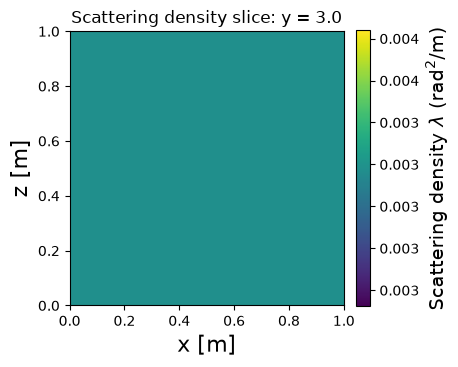

In [9]:
fig = scheduler.mapper.plot_slice(
    direction = 'y',
    value = 3.0,
    low = [dataset.low[0],dataset.low[2]],
    high = [dataset.high[0],dataset.high[2]],
    batch_size = 5000,
    points = 20,
    show_materials = True,
)
print ({name: 1/X0 for name,X0 in X0s.items()})
plt.show()

In [10]:
# # scheduler.n_samples=1
# sim_datasets,idx = scheduler.propagate(1000,no_grad=True)

# fig = scheduler.callbacks[2].on_observables_end(None,sim_datasets[0].observables,dataset.observables,dataset.observable_names)
# plt.show()

# sim_datasets[0].plot_3d(
#     N = 20,
#     arrow_scale=0.5,
#     show_direction=True,
#     show_path=True,                                                                                                                                                                                              
# )
# plt.show()

In [11]:
scheduler.optimize(n_iterations=10000)

Iteration 1/10000 [ 0.01]% - LR = 1.000e-02
Propagating batch of 10000x30 for mapper update
using torch.Size([300000, 3]) torch.Size([10000, 2000, 4])


IndexError: index 250000 is out of bounds for dimension 0 with size 10000

In [ ]:
scheduler.callbacks[0].plot(iteration=None)

In [ ]:
scheduler.callbacks[1].plot(iteration=None,mapper=scheduler.mapper)

In [ ]:
fig = mapper.plot_slice(
    direction = 'z',
    value = 2.5,
    low = dataset.low[:2],
    high = dataset.high[:2],
    batch_size = 5000,
    points = 20,
)
plt.show()

fig = mapper.plot_slice(
    direction = 'y',self.propagate(batch_size)
    value = 3.0,
    low = [dataset.low[0],dataset.low[2]],
    high = [dataset.high[0],dataset.high[2]],
    batch_size = 5000,
    points = 20,
)
plt.show()

In [ ]:
fig = mapper.plot_slice(
    direction = 'z',
    value = 2.5,
    low = dataset.low[:2],
    high = dataset.high[:2],
    batch_size = 5000,
    points = 20,
)
plt.show()

fig = mapper.plot_slice(
    direction = 'y',
    value = 3.0,
    low = [dataset.low[0],dataset.low[2]],
    high = [dataset.high[0],dataset.high[2]],
    batch_size = 5000,
    points = 20,
)
plt.show()

In [ ]:
scheduler.run(n_iterations=100,batch_size=256)

In [ ]:
scheduler.surrogate.validate_model(batch_size=1000)

In [ ]:
observables = positions_to_observables(
    ri = ri,
    rf = rf,
    di = di,
    df = df,
    lo = dataset.low,
    hi = dataset.high,
)
observables = torch.stack(observables,dim=1)
conditions = torch.cat([ri,di],dim=1)


In [ ]:
fig = scheduler.compare_observables(observables.detach())
plt.show()